Please upload the input image:


Saving sunset.jpg to sunset.jpg


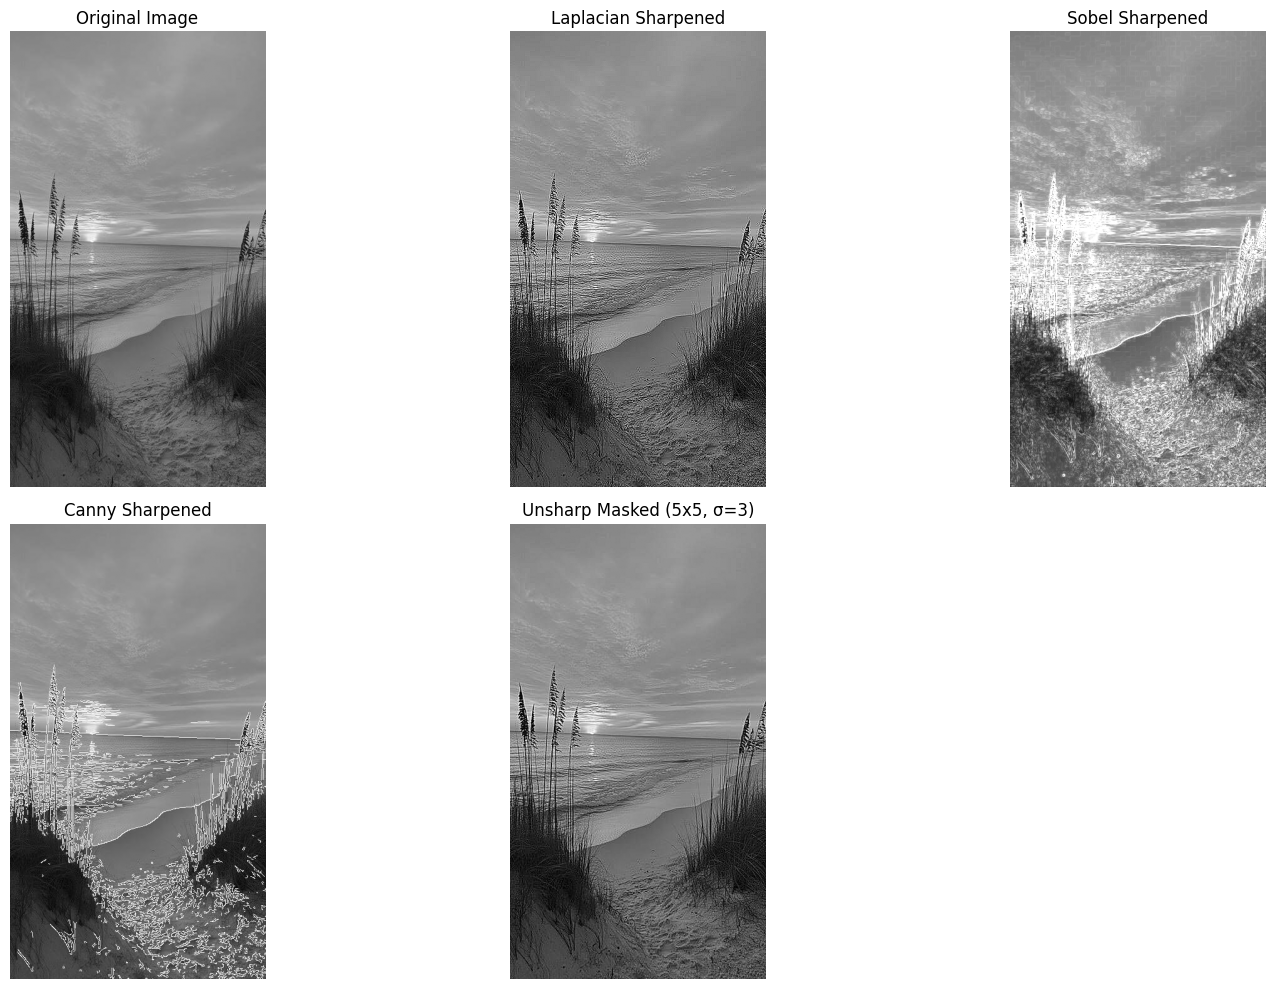

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


print("Please upload the input image:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

laplacian = cv2.Laplacian(img, cv2.CV_64F)

sharpened_laplacian = img.astype(np.float64) - laplacian
sharpened_laplacian = np.clip(sharpened_laplacian, 0, 255).astype(np.uint8)


sobel_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)

sharpened_sobel = img.astype(np.float64) + sobel_magnitude
sharpened_sobel = np.clip(sharpened_sobel, 0, 255).astype(np.uint8)

canny_edges = cv2.Canny(img, threshold1=100, threshold2=200)

sharpened_canny = img.astype(np.float64) + canny_edges.astype(np.float64)
sharpened_canny = np.clip(sharpened_canny, 0, 255).astype(np.uint8)


blurred = cv2.GaussianBlur(img, (5, 5), sigmaX=3, sigmaY=3)

mask = img.astype(np.float64) - blurred.astype(np.float64)

sharpened_unsharp = img.astype(np.float64) + mask
sharpened_unsharp = np.clip(sharpened_unsharp, 0, 255).astype(np.uint8)


titles = [
    'Original Image',
    'Laplacian Sharpened',
    'Sobel Sharpened',
    'Canny Sharpened',
    'Unsharp Masked (5x5, σ=3)'
]

images = [
    img,
    sharpened_laplacian,
    sharpened_sobel,
    sharpened_canny,
    sharpened_unsharp
]

plt.figure(figsize=(16, 10))
for i in range(5):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i], fontsize=12)
    plt.axis('off')

plt.tight_layout()
plt.show()